<a href="https://colab.research.google.com/github/huseyinTozluyurt/Flyrank-Internship-MachineLearning/blob/main/work/notebooks/milestone_6_model_performance_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[Open the project repository](https://github.com/huseyinTozluyurt/Flyrank-Internship-MachineLearning) · [Open this notebook in Google Colab](https://colab.research.google.com/github/huseyinTozluyurt/Flyrank-Internship-MachineLearning/blob/main/work/notebooks/milestone_6_model_performance_analysis.ipynb)

# Milestone 6 — Detailed model performance analysis

This stage analyzes the exact held-out predictions and consensus queues created in Milestone 5. It compares logistic regression with random forest on identical client-held-out pages. It does not refit models, change the feature contract, or create new splits.

The primary comparison is ranking performance: average precision and Precision/Recall/Lift/NDCG at review capacities of 20, 50, and 100. We also report fold-level score calibration summaries, paired split differences, client-level spread, and overlap of the aggregated consensus top-50 queues. Results are descriptive across five repeated grouped splits; overlapping folds mean they are not independent replications.

In [5]:
import subprocess
from pathlib import Path

# Ensure repository is cloned and directory is changed
if IN_COLAB:
    # Run the utility script or training script to populate predictions
    print("Running pipeline to generate Milestone 5 artifacts...")

    # List of scripts to run in sequence to produce models and predictions
    scripts = [
        'scripts/01_prepare_features.py',
        'scripts/02_baseline_score.py',
        'scripts/03_train_model.py',
        'scripts/04_evaluate_and_export.py'
    ]

    for script in scripts:
        if Path(script).exists():
            print(f"Executing {script}...")
            result = subprocess.run(['python', script], capture_output=True, text=True)
            if result.returncode != 0:
                print(f"Error executing {script}:\n", result.stderr)
            else:
                print(f"Successfully finished {script}")
        else:
            print(f"Script {script} not found.")

Running pipeline to generate Milestone 5 artifacts...
Executing scripts/01_prepare_features.py...
Successfully finished scripts/01_prepare_features.py
Executing scripts/02_baseline_score.py...
Successfully finished scripts/02_baseline_score.py
Executing scripts/03_train_model.py...
Successfully finished scripts/03_train_model.py
Executing scripts/04_evaluate_and_export.py...
Successfully finished scripts/04_evaluate_and_export.py


In [7]:
import os, sys, subprocess, json
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss, log_loss

IN_COLAB = 'google.colab' in sys.modules

if IN_COLAB:
    # Correctly target the outer repository directory where scripts ran
    target_dir = Path('/content/Flyrank-Internship-MachineLearning')
    if target_dir.exists():
        os.chdir(target_dir)
    print(f'Current working directory: {os.getcwd()}')
else:
    while not Path('work/notebooks/milestone_6_model_performance_analysis.ipynb').exists() and Path.cwd() != Path('/'):
        os.chdir('..')

M5_DIR = Path('work/outputs/milestone_5_action_playbook')
PREDICTIONS_PATH = M5_DIR / 'heldout_fold_predictions.csv'
LOGISTIC_QUEUE_PATH = M5_DIR / 'logistic_regression_review_queue.csv'
FOREST_QUEUE_PATH = M5_DIR / 'random_forest_review_queue.csv'

# Let's print the actual paths we are looking for to make debugging easy
print(f'Checking: {PREDICTIONS_PATH.resolve()}')

for path in [PREDICTIONS_PATH, LOGISTIC_QUEUE_PATH, FOREST_QUEUE_PATH]:
    if not path.exists():
        raise FileNotFoundError(f'{path} missing. Run Milestone 5 through its export cell first.')
heldout = pd.read_csv(PREDICTIONS_PATH)
logistic_queue = pd.read_csv(LOGISTIC_QUEUE_PATH)
forest_queue = pd.read_csv(FOREST_QUEUE_PATH)
required = {'content_id','client_id','is_declining_label','split','model','priority_score','rank'}
if not required.issubset(heldout.columns):
    raise ValueError(f'Milestone 5 prediction file is missing: {sorted(required - set(heldout.columns))}')
print(f'Loaded {len(heldout):,} held-out prediction rows; splits={sorted(heldout.split.unique())}; models={sorted(heldout.model.unique())}')

Current working directory: /content/Flyrank-Internship-MachineLearning
Checking: /content/Flyrank-Internship-MachineLearning/work/outputs/milestone_5_action_playbook/heldout_fold_predictions.csv
Loaded 58,788 held-out prediction rows; splits=[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]; models=['logistic_regression', 'random_forest']


## Checks: are the predictions paired?

Within each split, both models must score the exact same `content_id` and label rows. The check below verifies that before computing paired comparisons. Scores and ranks are not combined across folds for the fold-level metrics; each fold is evaluated separately, then summarized.

In [8]:
heldout['is_declining_label'] = pd.to_numeric(heldout['is_declining_label'],errors='raise').astype(int)
models = set(heldout['model'].unique())
expected_models = {'logistic_regression','random_forest'}
assert models == expected_models, f'Unexpected model set: {models}'
for split_id, fold in heldout.groupby('split'):
    by_model = {name: set(g['content_id']) for name,g in fold.groupby('model')}
    assert by_model['logistic_regression'] == by_model['random_forest'], f'Candidate mismatch in split {split_id}'
    assert not fold.duplicated(['model','content_id']).any(), f'Duplicate scored page within split {split_id}'
    label_counts = fold.groupby('content_id')['is_declining_label'].nunique()
    assert label_counts.max() == 1, f'Label mismatch in split {split_id}'
print('Pairing check passed: both models were evaluated on the same pages in every split.')

Pairing check passed: both models were evaluated on the same pages in every split.


## Ranking and score metrics

Precision@K measures how many selected pages carry the supplied decline label; Recall@K measures the share of all decline-labeled pages found in the top K. Lift@K compares Precision@K to that fold's base decline rate. NDCG@50 rewards placing positive pages nearer the top. Brier score and log loss describe probability quality; with class-weighted models, these outputs may need calibration before being read as literal probabilities.

In [9]:
def ranking_metrics(y, scores, k):
    y = np.asarray(y,dtype=int); scores = np.asarray(scores,dtype=float)
    order = np.argsort(-scores,kind='mergesort')
    n = min(k,len(y)); top = order[:n]
    precision = float(y[top].mean()) if n else np.nan
    total_positive = int(y.sum())
    recall = float(y[top].sum()/total_positive) if total_positive else np.nan
    base_rate = float(y.mean()) if len(y) else np.nan
    discounts = 1 / np.log2(np.arange(2,n+2))
    dcg = float(np.sum(y[top]*discounts))
    ideal_n = min(n,total_positive)
    idcg = float(np.sum(discounts[:ideal_n]))
    return {'precision_at_k':precision,'recall_at_k':recall,
            'lift_at_k':precision/base_rate if base_rate else np.nan,
            'ndcg_at_k':dcg/idcg if idcg else np.nan}

metric_rows=[]
for (split_id,model_name),g in heldout.groupby(['split','model']):
    y = g['is_declining_label'].to_numpy()
    scores = pd.to_numeric(g['priority_score'],errors='raise').to_numpy()
    row={'split':split_id,'model':model_name,'n_test':len(g),'decline_rate':float(y.mean()),
         'average_precision':float(average_precision_score(y,scores)),
         'roc_auc':float(roc_auc_score(y,scores)) if np.unique(y).size==2 else np.nan,
         'brier_score':float(brier_score_loss(y,scores)),
         'log_loss':float(log_loss(y,np.clip(scores,1e-8,1-1e-8),labels=[0,1]))}
    for k in [20,50,100]:
        row.update({f'{key}_{k}':value for key,value in ranking_metrics(y,scores,k).items()})
    metric_rows.append(row)

fold_metrics=pd.DataFrame(metric_rows)
metric_cols=[c for c in fold_metrics.columns if c not in ['split','model','n_test','decline_rate']]
summary=(fold_metrics.groupby('model')[metric_cols]
    .agg(['mean','std']).round(3))
display(fold_metrics.sort_values(['split','model']).round(3))
display(summary)

,split,model,n_test,decline_rate,average_precision,roc_auc,brier_score,log_loss,precision_at_k_20,recall_at_k_20,lift_at_k_20,ndcg_at_k_20,precision_at_k_50,recall_at_k_50,lift_at_k_50,ndcg_at_k_50,precision_at_k_100,recall_at_k_100,lift_at_k_100,ndcg_at_k_100
0,1,logistic_regression,7115,0.517,0.562,0.569,0.250,0.693,0.65,0.004,1.258,0.693,0.68,0.009,1.317,0.693,0.62,0.017,1.200,0.643
1,1,random_forest,7115,0.517,0.591,0.598,0.241,0.673,0.70,0.004,1.355,0.698,0.68,0.009,1.317,0.687,0.67,0.018,1.297,0.676
2,2,logistic_regression,10046,0.613,0.694,0.627,0.233,0.656,0.75,0.002,1.224,0.727,0.70,0.006,1.142,0.701,0.70,0.011,1.142,0.701
3,2,random_forest,10046,0.613,0.741,0.673,0.224,0.635,0.80,0.003,1.306,0.780,0.84,0.007,1.371,0.819,0.83,0.013,1.354,0.820
4,3,logistic_regression,5735,0.486,0.565,0.618,0.238,0.661,0.70,0.005,1.440,0.741,0.62,0.011,1.275,0.660,0.52,0.019,1.070,0.566
5,3,random_forest,5735,0.486,0.584,0.659,0.221,0.625,0.50,0.004,1.029,0.587,0.38,0.007,0.782,0.455,0.44,0.016,0.905,0.474
6,4,logistic_regression,3435,0.341,0.505,0.699,0.211,0.631,0.45,0.008,1.318,0.536,0.46,0.020,1.347,0.504,0.47,0.040,1.376,0.496
7,4,random_forest,3435,0.341,0.570,0.748,0.200,0.575,0.60,0.010,1.757,0.672,0.74,0.032,2.167,0.746,0.68,0.058,1.991,0.696
8,5,logistic_regression,3063,0.442,0.525,0.615,0.240,0.671,0.70,0.010,1.584,0.753,0.64,0.024,1.448,0.683,0.53,0.039,1.199,0.582
9,5,random_forest,3063,0.442,0.564,0.642,0.236,0.663,0.75,0.011,1.697,0.763,0.60,0.022,1.357,0.643,0.66,0.049,1.493,0.673


average_precision        roc_auc        brier_score  \
                                 mean    std    mean    std        mean   
model                                                                     
logistic_regression              0.57  0.074   0.626  0.047       0.234   
random_forest                    0.61  0.074   0.664  0.055       0.224   

                           log_loss        precision_at_k_20         ...  \
                       std     mean    std              mean    std  ...   
model                                                                ...   
logistic_regression  0.014    0.662  0.022              0.65  0.117  ...   
random_forest        0.016    0.634  0.038              0.67  0.120  ...   

                    ndcg_at_k_50        precision_at_k_100         \
                            mean    std               mean    std   
model                                                               
logistic_regression        0.648  0.082              0.568  0.091   
random_forest              0.670  0.137              0.656  0.139   

                    recall_at_k_100        lift_at_k_100        ndcg_at_k_100  \
                               mean    std          mean    std          mean   
model                                                                           
logistic_regression           0.025  0.013         1.198  0.113         0.598   
random_forest                 0.031  0.021         1.408  0.392         0.668   

                            
                       std  
model                       
logistic_regression  0.078  
random_forest        0.124  

[2 rows x 32 columns]

## Paired fold deltas and client variation

Paired deltas compare random forest minus logistic regression inside each identical split. We report the mean delta, its standard deviation, and how often each model wins across the five splits; this is descriptive, not a significance test. Client-level average precision is shown only when that held-out client contains both labels.

In [12]:
paired = fold_metrics.pivot(index='split',columns='model',values=['average_precision','precision_at_k_50','recall_at_k_50','ndcg_at_k_50','brier_score'])
delta_rows=[]
for metric in ['average_precision','precision_at_k_50','recall_at_k_50','ndcg_at_k_50','brier_score']:
    d=paired[(metric,'random_forest')]-paired[(metric,'logistic_regression')]
    lower_is_better = metric in ['brier_score']
    delta_rows.append({'metric':'random_forest_minus_logistic_'+metric,'mean_delta':d.mean(),
                       'sd_delta':d.std(),'lower_is_better':lower_is_better,
                       'rf_wins':int((d<0).sum()) if lower_is_better else int((d>0).sum()),
                       'logistic_wins':int((d>0).sum()) if lower_is_better else int((d<0).sum()),
                       'ties':int((d==0).sum()),'splits':int(d.notna().sum())})
paired_deltas=pd.DataFrame(delta_rows)
display(paired_deltas.round(4))

client_rows=[]
for (split_id,model_name,client_id),g in heldout.groupby(['split','model','client_id']):
    y=g['is_declining_label'].to_numpy(); scores=g['priority_score'].to_numpy()
    client_rows.append({'split':split_id,'model':model_name,'client_id':client_id,'n_pages':len(g),
        'decline_rate':float(y.mean()),'average_precision':float(average_precision_score(y,scores)) if np.unique(y).size==2 else np.nan,
        'precision_at_10':ranking_metrics(y,scores,10)['precision_at_k']})
client_metrics=pd.DataFrame(client_rows)
client_summary=(client_metrics.groupby('model').agg(heldout_client_rows=('client_id','count'),
    mean_client_decline_rate=('decline_rate','mean'),sd_client_decline_rate=('decline_rate','std'),
    mean_client_average_precision=('average_precision','mean'),sd_client_average_precision=('average_precision','std'),
    mean_client_precision_at_10=('precision_at_10','mean')).round(3))
display(client_summary)

,metric,mean_delta,sd_delta,lower_is_better,rf_wins,logistic_wins,ties,splits
0,random_forest_minus_logistic_average_precision,0.0400,0.0177,False,5,0,0,5
1,random_forest_minus_logistic_precision_at_k_50,0.0280,0.1958,False,2,2,1,5
2,random_forest_minus_logistic_recall_at_k_50,0.0015,0.0062,False,2,2,1,5
3,random_forest_minus_logistic_ndcg_at_k_50,0.0219,0.1689,False,2,3,0,5
4,random_forest_minus_logistic_brier_score,-0.0100,0.0046,True,5,0,0,5


,heldout_client_rows,mean_client_decline_rate,sd_client_decline_rate,mean_client_average_precision,sd_client_average_precision,mean_client_precision_at_10
model,,,,,,
logistic_regression,40,0.456,0.213,0.539,0.180,0.54
random_forest,40,0.456,0.213,0.564,0.184,0.57


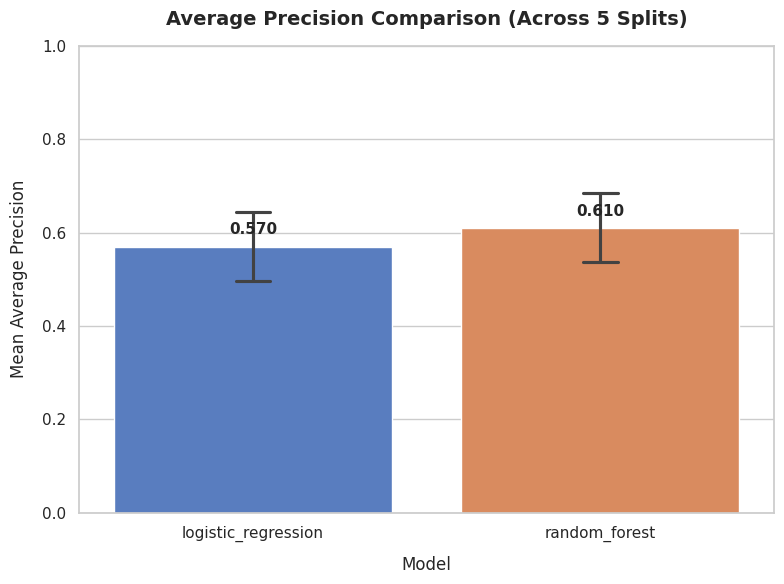

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter fold_metrics for average_precision
ap_metrics = fold_metrics[['model', 'average_precision']]

# Configure plot style
sns.set_theme(style='whitegrid')
fig, ax = plt.subplots(figsize=(8, 6))

# Draw bar plot showing mean with standard deviation as error bars
sns.barplot(
    x='model',
    y='average_precision',
    data=ap_metrics,
    errorbar='sd',
    capsize=0.1,
    palette='muted',
    hue='model',
    legend=False,
    ax=ax
)

ax.set_title('Average Precision Comparison (Across 5 Splits)', fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('Model', fontsize=12, labelpad=10)
ax.set_ylabel('Mean Average Precision', fontsize=12, labelpad=10)
ax.set_ylim(0, 1.0)

# Annotate exact mean values on top of the bars
means = ap_metrics.groupby('model')['average_precision'].mean()
for i, model_name in enumerate(means.index):
    ax.text(i, means[model_name] + 0.02, f"{means[model_name]:.3f}", ha='center', va='bottom', fontweight='bold', fontsize=11)

plt.tight_layout()
plt.show()

## Consensus queue comparison

The two Milestone 5 queues contain the same candidate population but may rank it differently. We compare their consensus top-50 overlap and descriptive label precision. Because the top pages were selected using the same repeated predictions whose labels are reported here, consensus precision is exploratory; use the per-split held-out metrics above for model comparison. Raw probability averages are not used to compare model order because the models can produce differently calibrated scores.

In [13]:
# Add labels from the held-out predictions without changing either queue's ranking.
labels=heldout[['content_id','client_id','is_declining_label']].drop_duplicates(['content_id','client_id'])
def queue_top50(queue,name):
    q=queue.sort_values('queue_rank').head(50).merge(labels,on=['content_id','client_id'],how='left',validate='one_to_one')
    if q['is_declining_label'].isna().any(): raise ValueError(f'Unlabeled candidates in {name} queue.')
    return q
log_top50=queue_top50(logistic_queue,'logistic')
rf_top50=queue_top50(forest_queue,'random forest')
log_ids=set(log_top50['content_id']); rf_ids=set(rf_top50['content_id'])
intersection=log_ids & rf_ids
union=log_ids | rf_ids
consensus_summary=pd.DataFrame([
 {'model':'logistic_regression','queue_size':len(log_top50),'label_precision_at_50':log_top50['is_declining_label'].mean()},
 {'model':'random_forest','queue_size':len(rf_top50),'label_precision_at_50':rf_top50['is_declining_label'].mean()},
 {'model':'shared_top50','queue_size':len(intersection),'label_precision_at_50':
  pd.concat([log_top50[log_top50.content_id.isin(intersection)],rf_top50[rf_top50.content_id.isin(intersection)]]).drop_duplicates('content_id')['is_declining_label'].mean() if intersection else np.nan}
])
print(f'Top-50 overlap: {len(intersection)} pages; Jaccard={len(intersection)/len(union):.3f}')
display(consensus_summary.round(3))
reason_summary=pd.concat([
    log_top50.assign(model='logistic_regression'),rf_top50.assign(model='random_forest')
]).groupby(['model','reason_codes'],dropna=False).agg(pages=('content_id','count'),
    observed_decline_rate=('is_declining_label','mean')).reset_index().sort_values(['model','pages'],ascending=[True,False])
display(reason_summary.round(3))

Top-50 overlap: 5 pages; Jaccard=0.053


,model,queue_size,label_precision_at_50
0,logistic_regression,50,0.74
1,random_forest,50,0.76
2,shared_top50,5,0.80


,model,reason_codes,pages,observed_decline_rate
1,logistic_regression,MODEL_PRIORITY_REVIEW_CONTEXT_FIRST,28,0.750
4,logistic_regression,STALE_WITH_TRAFFIC_REVIEW_UPDATE_HISTORY,14,0.643
2,logistic_regression,POSITION_DANGER_BAND_REVIEW_SERP,5,0.800
0,logistic_regression,HIGH_VISIBILITY_VALIDATE_IMPACT,2,1.000
3,logistic_regression,POSITION_DANGER_BAND_REVIEW_SERP;STALE_WITH_TR...,1,1.000
5,random_forest,HIGH_VISIBILITY_VALIDATE_IMPACT,32,0.844
7,random_forest,POSITION_DANGER_BAND_REVIEW_SERP,11,0.545
6,random_forest,MODEL_PRIORITY_REVIEW_CONTEXT_FIRST,7,0.714


## Interpretation

Prefer the model based on the intended capacity and the grouped holdout evidence: Precision@50 is directly relevant to a 50-page review queue, while average precision summarizes ranking across the full held-out set. Consider the fold and client spread alongside the means. A model with a small average edge and inconsistent split wins is not clearly better.

Neither result establishes a future-warning system. Before a production claim, use dated feature windows and a later temporal holdout, calibrate scores if interpreted as probabilities, and evaluate whether editorial actions improve outcomes.

In [14]:
OUTPUT_DIR=Path('work/outputs/milestone_6_model_performance_analysis')
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)
fold_metrics.to_csv(OUTPUT_DIR/'fold_level_performance.csv',index=False)
paired_deltas.to_csv(OUTPUT_DIR/'paired_fold_deltas.csv',index=False)
client_metrics.to_csv(OUTPUT_DIR/'client_level_performance.csv',index=False)
consensus_summary.to_csv(OUTPUT_DIR/'consensus_top50_comparison.csv',index=False)
reason_summary.to_csv(OUTPUT_DIR/'top50_reason_code_summary.csv',index=False)
contract={
 'source':'Milestone 5 held-out_fold_predictions.csv and consensus queue exports',
 'comparison':'logistic regression vs random forest on same held-out rows within each split',
 'splits':'five repeated GroupShuffleSplit folds from Milestone 5; folds overlap and are not independent',
 'primary_metrics':['average_precision','precision_at_50','recall_at_50','ndcg_at_50'],
 'secondary_metrics':['roc_auc','precision/recall/lift/ndcg at 20 and 100','brier_score','log_loss','client-level spread'],
 'consensus_queue_metrics':'descriptive only; same repeated predictions used to rank pages',
 'scope':'current-label prioritization; not future prediction or causal evaluation'
}
(OUTPUT_DIR/'performance_analysis_contract.json').write_text(json.dumps(contract,indent=2)+'\n',encoding='utf-8')
print('Saved Stage 6 results to',OUTPUT_DIR.resolve())

Saved Stage 6 results to /content/Flyrank-Internship-MachineLearning/work/outputs/milestone_6_model_performance_analysis
